# CM2 vs OM2: mean-state comparison

**What's in this notebook**

- Mean-state maps of uas, vas and tas.
- Compares ERA5, JRA55-do and ACCESS-CM2.

_Split from `plots_cm2_om2_compare.ipynb`. Shared helpers in `functions.py`; outputs stripped — re-run to regenerate figures._


In [1]:
# Load Packages 

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import math
import cartopy.crs as ccrs
import calendar
from matplotlib.lines import Line2D
import os
import re
import seaborn as sns
import pandas as pd
import matplotlib.gridspec as gridspec
from scipy.stats import norm
# from mpl_toolkits.basemap import Basemap
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.patches as patches
from scipy.stats import scoreatpercentile
# import xesmf as xe
from matplotlib.gridspec import GridSpec
import matplotlib

%matplotlib inline


In [2]:
import sys, os
# make this repo's functions.py importable from any subfolder
_p = os.getcwd()
for _ in range(6):
    if os.path.exists(os.path.join(_p, 'functions.py')):
        sys.path.insert(0, _p); break
    _p = os.path.dirname(_p)
from functions import *  # shared helper functions


In [3]:
# Load variables produced by earlier (compute/loader) notebooks.
# Run those first; harmless if there's nothing saved yet.
load_state(globals())


[load_state] loaded 215 variables from /Users/isabelaconde/Documents/GitHub/JRA55-do_ctrl_ERA5-forcings/processed_data/state.pkl
[load_state] available: DA_all, In, Out, STATE_DIR, STATE_FILE, all_trend_percentiles, ax, basin_cmip, basin_era5, basin_jra55, basin_noaa, basin_omip ...


{'In': ['',
  "# Load Packages\nimport numpy as np\nimport xarray as xr\nimport matplotlib\nimport matplotlib.pyplot as plt\nimport matplotlib.transforms as transforms\nimport cartopy.crs as ccrs\nimport calendar, os, re, datetime\nfrom datetime import datetime as _dt\nfrom pathlib import Path\nfrom matplotlib.lines import Line2D\nimport seaborn as sns\nimport pandas as pd\nimport matplotlib.gridspec as gridspec\nfrom scipy.stats import norm, scoreatpercentile\nfrom mpl_toolkits.axes_grid1 import make_axes_locatable\nimport matplotlib.patches as patches\nfrom matplotlib.gridspec import GridSpec\nfrom xhistogram.xarray import histogram\n\nget_ipython().run_line_magic('matplotlib', 'inline')",
  "import sys, os\n_p = os.getcwd()\nfor _ in range(6):\n    if os.path.exists(os.path.join(_p, 'functions.py')):\n        sys.path.insert(0, _p); break\n    _p = os.path.dirname(_p)\nfrom functions import *  # shared helper functions",
  "def quantiles_xhist(data):\n    hist_T = data.sel(lon = sli

# Plots of means 

In [4]:
era5_uas = xr.open_dataset('/Users/isabelaconde/Desktop/data/ERA5/mean/ERA5_u10_mean_1982-2018_gr.nc').uas
era5_vas = xr.open_dataset('/Users/isabelaconde/Desktop/data/ERA5/mean/ERA5_v10_mean_1982-2018_gr.nc').vas

jra55_uas  = xr.open_dataset('/Users/isabelaconde/Desktop/data/JRA55/means/JRA55-do_uas-mean_1982-2018_gr.nc').uas
jra55_vas  = xr.open_dataset('/Users/isabelaconde/Desktop/data/JRA55/means/JRA55-do_vas-mean_1982-2018_gr.nc').vas

/var/folders/3m/hb6030nd3ml4fk_t3lq08f4w0000gn/T/ipykernel_93338/2042174464.py:54: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.90, 1], pad=0.2)


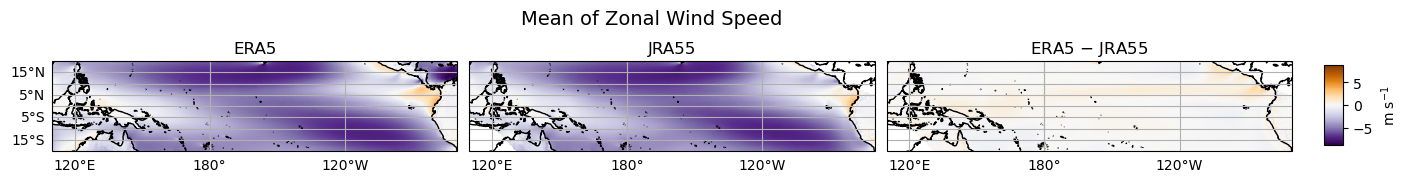

In [5]:
# uas
# target grid = ERA5
lat, lon = era5_uas.lat, era5_uas.lon
on_era5  = lambda da: da.interp(lat=lat, lon=lon)

era5  = era5_uas
jra55 = on_era5(jra55_uas)   # <-- was jra55_tas

das = [
    ("ERA5",            era5 ),
    ("JRA55",           jra55 ),
    (r"ERA5 $-$ JRA55", (era5 - jra55 ) ),
]

# --- common colour limits (symmetric about 0) ---
stack = xr.concat([d for _, d in das], dim="panel")
v = float(np.nanmax(np.abs(stack.values)))
vmin, vmax = -v, v  # symmetric

# --- map setup (same style as your final 1x3 example) ---
proj = ccrs.PlateCarree(central_longitude=180)
pc0  = ccrs.PlateCarree()
extent = [110, 290, -20, 20]

fig = plt.figure(figsize=(16, 2))
gs = GridSpec(1, 3, figure=fig, wspace=0.03)

axes = [fig.add_subplot(gs[0, c], projection=proj) for c in range(3)]

ims = []
for ax, (title, da) in zip(axes, das):
    im = ax.pcolormesh(
        da.lon, da.lat, da,
        cmap="PuOr_r", vmin=vmin, vmax=vmax,
        transform=pc0
    )
    ax.set_extent(extent, crs=pc0)
    ax.coastlines()
    ax.set_title(title, fontsize=12)
    ims.append(im)

# gridlines: labels only on leftmost
for i, ax in enumerate(axes):
    gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
    gl.top_labels = False
    gl.right_labels = False
    if i != 0:
        gl.left_labels = False

# colorbar
cax = fig.add_axes([0.92, 0.30, 0.012, 0.40])
fig.colorbar(ims[0], cax=cax, label=r'm s$^{-1}$')

plt.tight_layout(rect=[0, 0, 0.90, 1], pad=0.2)
plt.suptitle('Mean of Zonal Wind Speed', fontsize=14, y=0.98)  # <-- was Surface Air Temperature
plt.show()
# plt.suptitle('Trend of Surface Air Temperature', fontsize=14, y=0.98)
plt.show()



/var/folders/3m/hb6030nd3ml4fk_t3lq08f4w0000gn/T/ipykernel_93338/2910542610.py:54: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.90, 1], pad=0.2)


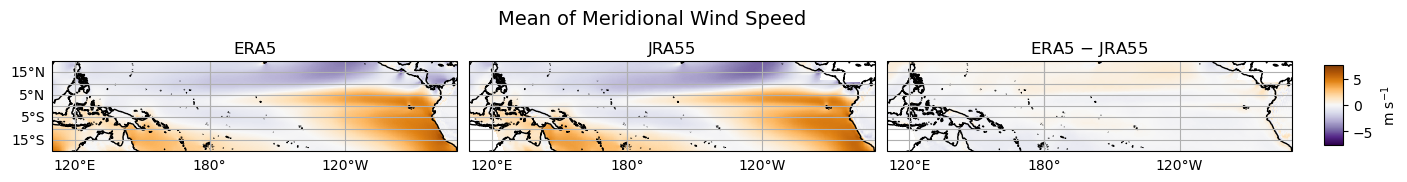

In [6]:
# vas
# target grid = ERA5
lat, lon = era5_vas.lat, era5_vas.lon
on_era5  = lambda da: da.interp(lat=lat, lon=lon)

era5  = era5_vas
jra55 = on_era5(jra55_vas)

das = [
    ("ERA5",            era5),
    ("JRA55",           jra55),
    (r"ERA5 $-$ JRA55", (era5 - jra55)),
]

# --- common colour limits (symmetric about 0) ---
stack = xr.concat([d for _, d in das], dim="panel")
v = float(np.nanmax(np.abs(stack.values)))
vmin, vmax = -v, v  # symmetric

# --- map setup (same style as your final 1x3 example) ---
proj = ccrs.PlateCarree(central_longitude=180)
pc0  = ccrs.PlateCarree()
extent = [110, 290, -20, 20]

fig = plt.figure(figsize=(16, 2))
gs = GridSpec(1, 3, figure=fig, wspace=0.03)

axes = [fig.add_subplot(gs[0, c], projection=proj) for c in range(3)]

ims = []
for ax, (title, da) in zip(axes, das):
    im = ax.pcolormesh(
        da.lon, da.lat, da,
        cmap="PuOr_r", vmin=vmin, vmax=vmax,
        transform=pc0
    )
    ax.set_extent(extent, crs=pc0)
    ax.coastlines()
    ax.set_title(title, fontsize=12)
    ims.append(im)

# gridlines: labels only on leftmost
for i, ax in enumerate(axes):
    gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
    gl.top_labels = False
    gl.right_labels = False
    if i != 0:
        gl.left_labels = False

# colorbar
cax = fig.add_axes([0.92, 0.30, 0.012, 0.40])
fig.colorbar(ims[0], cax=cax, label=r'm s$^{-1}$')

plt.tight_layout(rect=[0, 0, 0.90, 1], pad=0.2)
plt.suptitle('Mean of Meridional Wind Speed', fontsize=14, y=0.98)
plt.show()



In [ ]:
# target grid = ERA5
lat, lon = era5_uas.lat, era5_uas.lon
on_era5 = lambda da: da.interp(lat=lat, lon=lon)

era5 = era5_uas
exp  = era5_uas + 0.15/10/12
diff = exp - era5

das = [
    ("ERA5", era5 * 10 * 12),
    ("Proposed exp", exp * 10 * 12),
    (r"Proposed exp $-$ ERA5", diff * 10 * 12),
]

vmin, vmax = -0.5, 0.5

proj = ccrs.PlateCarree(central_longitude=180)
pc0  = ccrs.PlateCarree()
extent = [110, 290, -20, 20]

n = len(das)

fig = plt.figure(figsize=(5 * n, 2))
gs = GridSpec(1, n, figure=fig, wspace=0.03)

axes = [fig.add_subplot(gs[0, i], projection=proj) for i in range(n)]

ims = []
for i, (ax, (title, da)) in enumerate(zip(axes, das)):
    im = ax.pcolormesh(
        da.lon, da.lat, da,
        cmap="PuOr_r",
        vmin=vmin, vmax=vmax,
        transform=pc0
    )
    ax.set_extent(extent, crs=pc0)
    ax.coastlines()
    ax.set_title(title, fontsize=12)

    gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
    gl.top_labels = False
    gl.right_labels = False
    if i != 0:
        gl.left_labels = False

    ims.append(im)

cax = fig.add_axes([0.92, 0.2, 0.015, 0.6])
fig.colorbar(ims[0], cax=cax, label=r'm s$^{-1}$ (10 yr)$^{-1}$')

fig.suptitle('Trend of Zonal Wind Speed', fontsize=14, y=0.95)
plt.tight_layout(rect=[0, 0, 0.9, 1])
plt.show()

In [ ]:

lat, lon = era5_vas.lat, era5_vas.lon
on_era5  = lambda da: da.interp(lat=lat, lon=lon)


era5 = era5_vas
exp  = era5_vas + 0.1/10/12
diff = exp - era5

das = [
    ("ERA5", era5 * 10 * 12),
    ("Proposed exp", exp * 10 * 12),
    (r"Proposed exp $-$ ERA5", diff * 10 * 12),
]
stack = xr.concat([d for _, d in das], dim="panel")
v = 0.5
vmin, vmax = -v, v  # symmetric

proj = ccrs.PlateCarree(central_longitude=180)
pc0  = ccrs.PlateCarree()
extent = [110, 290, -20, 20]

fig = plt.figure(figsize=(16, 2))
gs = GridSpec(1, 3, figure=fig, wspace=0.03)

axes = [fig.add_subplot(gs[0, c], projection=proj) for c in range(3)]

ims = []
for ax, (title, da) in zip(axes, das):
    im = ax.pcolormesh(
        da.lon, da.lat, da,
        cmap="PuOr_r", vmin=vmin, vmax=vmax,
        transform=pc0
    )
    ax.set_extent(extent, crs=pc0)
    ax.coastlines()
    ax.set_title(title, fontsize=12)
    ims.append(im)

# gridlines: labels only on leftmost
for i, ax in enumerate(axes):
    gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
    gl.top_labels = False
    gl.right_labels = False
    if i != 0:
        gl.left_labels = False

# colorbar
cax = fig.add_axes([0.92, 0.30, 0.012, 0.40])
fig.colorbar(ims[0], cax=cax, label=r'm s$^{-1}$ (10 yr)$^{-1}$')

plt.tight_layout(rect=[0, 0, 0.90, 1], pad=0.2)
plt.suptitle('Trend of Meridional Wind Speed', fontsize=14, y=0.98)
plt.show()


In [ ]:

# target grid = ERA5
lat, lon = era5_tas.lat, era5_tas.lon
on_era5  = lambda da: da.interp(lat=lat, lon=lon)

era5  = era5_tas #*0 + 0.01/12
exp = era5_tas*0 + 0.016/12

das = [
    ("ERA5",            era5 * 10 * 12),
    ("proposed exp",         exp * 10 * 12),
    (r"proposed exp $-$ ERA5", (exp - era5) * 10 * 12),
    
]

# --- common colour limits (symmetric about 0) ---
stack = xr.concat([d for _, d in das], dim="panel")
v = 0.6
vmin, vmax = -v, v  # symmetric

# --- map setup (same style as your final 1x3 example) ---
proj = ccrs.PlateCarree(central_longitude=180)
pc0  = ccrs.PlateCarree()
extent = [110, 290, -20, 20]

fig = plt.figure(figsize=(16, 2))
gs = GridSpec(1, 3, figure=fig, wspace=0.03)

axes = [fig.add_subplot(gs[0, c], projection=proj) for c in range(3)]

ims = []
for ax, (title, da) in zip(axes, das):
    im = ax.pcolormesh(
        da.lon, da.lat, da,
        cmap="RdBu_r", vmin=vmin, vmax=vmax,
        transform=pc0
    )
    ax.set_extent(extent, crs=pc0)
    ax.coastlines()
    ax.set_title(title, fontsize=12)
    ims.append(im)

# gridlines: labels only on leftmost
for i, ax in enumerate(axes):
    gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
    gl.top_labels = False
    gl.right_labels = False
    if i != 0:
        gl.left_labels = False

# colorbar
cax = fig.add_axes([0.92, 0.30, 0.012, 0.40])
fig.colorbar(ims[0], cax=cax, label=r'C$^{\circ}$ (10 yr)$^{-1}$')

plt.tight_layout(rect=[0, 0, 0.90, 1], pad=0.2)
plt.suptitle('Trend of Surface Air Temperature', fontsize=14, y=0.98)
plt.show()


In [ ]:
# Save this notebook's variables so later (plotting) notebooks can load them.
save_state(globals())
